# Big Data Analytics: Credit Card Fraud Detection Production Pipeline
### Hybrid Architecture Combining Resampling, Robust Scaling, Non-linear Interactions, and Cost-Sensitive Multi-Model Benchmarking

**Course:** Big Data Analytics (BDA)  
**Dataset:** Credit Card Fraud Detection (284,807 transactions, European Cardholders)  
**Objective:** Engineer a leak-free, production-grade fraud detection pipeline that solves severe class imbalance (0.17% fraud prevalence) through domain-informed feature engineering, multi-algorithm benchmarking, decision threshold tuning, and business cost-utility analysis.


## 1. Problem Statement & Pipeline Architecture
In transactional credit card systems, fraud detection faces two major hurdles:
1. **Extreme Class Imbalance:** Fraud represents only **0.173%** (492 out of 284,807) of transactions. Traditional accuracy is meaningless (predicting all zeros yields 99.83% accuracy).
2. **The Data Leakage Trap:** Many public notebooks apply oversampling (SMOTE) or feature scaling *before* train-test splitting or cross-validation. This synthesizes test points using training samples and artificially tests models on a balanced (e.g., 34% or 50% fraud) distribution, causing disastrous failure when deployed in real-world environments.

Our **Production Hybrid Pipeline** addresses this by:
* **Feature Engineering:** Integrating `RobustScaler` (Notebook 1), 24-hour cyclical time features (Notebook 3), log-transformed amount, and critical PCA interaction terms (`V14`, `V12`, `V10`, `V17`).
* **Strict Leak-Free Protocol:** Holding out an untouched 20% test set with the natural 0.17% fraud rate.
* **Multi-Model Benchmarking:** Comparing Cost-Sensitive Logistic Regression, Balanced Random Forest, Histogram Gradient Boosting, and a Multi-Layer Perceptron (MLP) Neural Network.
* **Threshold Optimization:** Tuning decision thresholds using Precision-Recall trade-offs rather than the arbitrary 0.5 cutoff.


## 2. Environment Setup & Data Ingestion


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from src.feature_engineering import FraudFeatureEngineer
from src.pipeline import FraudDetectionPipeline
from src.evaluation import evaluate_model, find_optimal_threshold, plot_curves, plot_confusion_matrix_grid

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

CSV_PATH = "creditcard.csv"
df = pd.read_csv(CSV_PATH)

print(f"Dataset successfully loaded: {df.shape[0]:,} rows, {df.shape[1]} columns.")
df.head()


Dataset successfully loaded: 284,807 rows, 31 columns.
Out[1]: 
   Time        V1        V2        V3  ...       V27       V28  Amount  Class
0   0.0 -1.359807 -0.072781  2.536347  ...  0.133558 -0.021053  149.62      0
1   0.0  1.191857  0.266151  0.166480  ... -0.008983  0.014724    2.69      0
2   1.0 -1.358354 -1.340163  1.773209  ... -0.055353 -0.059752  378.66      0
3   1.0 -0.966272 -0.185226  1.792993  ...  0.062723  0.061458  123.50      0
4   2.0 -1.158233  0.877737  1.548718  ...  0.219422  0.215153   69.99      0

[5 rows x 31 columns]


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploratory Data Analysis & Target Imbalance


Genuine Transactions (Class 0): 284,315 (99.827%)
Fraudulent Transactions (Class 1): 492 (0.173%)
Imbalance Ratio: 1 fraud for every 577 genuine transactions.
Total Missing / Null Values: 0


<ipython-input-2-25131afa2115>:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, palette=['#2b5c8f', '#d9534f'], ax=ax1)
<ipython-input-2-25131afa2115>:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(['Normal (0)', 'Fraud (1)'])
<ipython-input-2-25131afa2115>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df, palette=['#2b5c8f', '#d9534f'], showfliers=False, ax=ax2)
<ipython-input-2-25131afa2115>:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.s

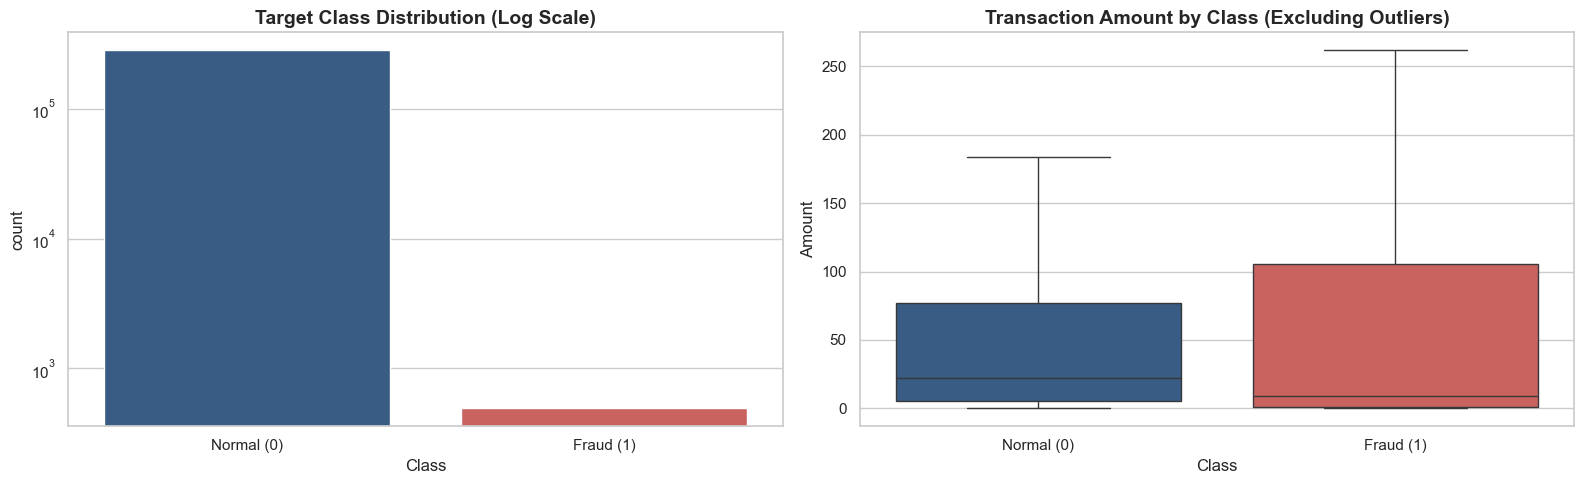

In [2]:
n_normal = (df['Class'] == 0).sum()
n_fraud = (df['Class'] == 1).sum()
pct_fraud = (n_fraud / len(df)) * 100

print(f"Genuine Transactions (Class 0): {n_normal:,} ({100 - pct_fraud:.3f}%)")
print(f"Fraudulent Transactions (Class 1): {n_fraud:,} ({pct_fraud:.3f}%)")
print(f"Imbalance Ratio: 1 fraud for every {n_normal // n_fraud} genuine transactions.")

# Null value check across all columns
null_count = df.isnull().sum().sum()
print(f"Total Missing / Null Values: {null_count}")

# Distribution visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Target count plot
sns.countplot(x='Class', data=df, palette=['#2b5c8f', '#d9534f'], ax=ax1)
ax1.set_yscale('log')
ax1.set_title('Target Class Distribution (Log Scale)', fontsize=14, fontweight='bold')
ax1.set_xticklabels(['Normal (0)', 'Fraud (1)'])

# Amount comparison
sns.boxplot(x='Class', y='Amount', data=df, palette=['#2b5c8f', '#d9534f'], showfliers=False, ax=ax2)
ax2.set_title('Transaction Amount by Class (Excluding Outliers)', fontsize=14, fontweight='bold')
ax2.set_xticklabels(['Normal (0)', 'Fraud (1)'])
plt.tight_layout()
plt.show()


## 4. Domain Feature Engineering (Hybrid Synthesis)
We apply domain transformations combining lessons from Notebooks 1, 2, and 3:
1. **`RobustScaler`** on `Amount` and `Time` using median and IQR.
2. **Log-transformation** on `Amount` (`log1p`) to compress its massive right skew ($0 to $25k).
3. **24-hour Cyclical Time** (`sin`/`cos` periodic features) reflecting temporal spending patterns.
4. **PCA Non-linear Interactions** (`V14_x_V12`, `V14_x_V17`, `V10_x_V11`) targeting highest discriminating variance directions.
5. **Extreme Anomaly Flags** identifying severe negative tails on `V14`, `V12`, `V10`.


In [3]:
fe = FraudFeatureEngineer()
sample_engineered = fe.fit_transform(df.drop(columns=['Class']).iloc[:1000])

print(f"Original Feature Count:    {df.shape[1] - 1}")
print(f"Engineered Feature Count:  {sample_engineered.shape[1]}")
print("\nNewly Engineered Features:")
for col in sample_engineered.columns[30:]:
    print(f" - {col}")


Original Feature Count:    30
Engineered Feature Count:  41

Newly Engineered Features:
 - Hour_sin
 - Hour_cos
 - Log_Amount
 - V14_x_V12
 - V14_x_V17
 - V10_x_V11
 - V4_x_V11
 - V14_extreme_neg
 - V12_extreme_neg
 - V10_extreme_neg
 - V4_extreme_pos


## 5. Strict Stratified Partitioning (Zero Data Leakage)
To prevent the catastrophic evaluation trap seen in public notebooks, we hold out an untouched **20% test set** with the true, natural 0.17% fraud prevalence.
Training data (80%) is split into 70% Train and 10% Validation (for threshold tuning).


In [4]:
X = df.drop(columns=['Class'])
y = df['Class']

# Stratified Split: 80% Train+Val, 20% Holdout Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Further split 80% Train+Val into 70% Train and 10% Validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.125, stratify=y_train_val, random_state=42
)

print(f"Train Set:      {len(X_train):,} samples | Frauds: {y_train.sum()} ({y_train.mean()*100:.3f}%)")
print(f"Validation Set: {len(X_val):,} samples | Frauds: {y_val.sum()} ({y_val.mean()*100:.3f}%)")
print(f"Holdout Test:   {len(X_test):,} samples | Frauds: {y_test.sum()} ({y_test.mean()*100:.3f}%)")


Train Set:      199,364 samples | Frauds: 345 (0.173%)
Validation Set: 28,481 samples | Frauds: 49 (0.172%)
Holdout Test:   56,962 samples | Frauds: 98 (0.172%)


## 6. Multi-Model Pipeline Training & Validation Threshold Tuning


In [5]:
models_to_train = {
    "logreg": "Logistic Regression (Cost-Sensitive)",
    "rf": "Random Forest (Balanced Subsample)",
    "hgb": "HistGradientBoosting (Balanced)",
    "mlp": "Neural Network (MLP Classifier)"
}

trained_pipelines = {}
test_predictions = {}
test_probabilities = {}
benchmark_data = []
eval_results = []

for m_key, m_label in models_to_train.items():
    print(f"Training {m_label}...")
    t0 = time.time()
    pipe = FraudDetectionPipeline(model_type=m_key)
    pipe.fit(X_train, y_train, tune_thresh=True, X_val=X_val, y_val=y_val)
    t_train = time.time() - t0
    
    probs = pipe.predict_proba(X_test)
    test_probabilities[m_label] = probs
    trained_pipelines[m_key] = pipe
    
    # Evaluate at Tuned Threshold
    res = evaluate_model(y_test, probs, threshold=pipe.threshold, model_name=m_label)
    eval_results.append(res)
    
    # Evaluate at Default 0.5 Threshold
    res_def = evaluate_model(y_test, probs, threshold=0.5, model_name=m_label)
    
    benchmark_data.append({
        "Algorithm": m_label,
        "Train Time (s)": round(t_train, 2),
        "PR-AUC": round(res["pr_auc"], 4),
        "ROC-AUC": round(res["roc_auc"], 4),
        "Tuned Threshold": round(pipe.threshold, 4),
        "Tuned F1-Score": round(res["f1_score"], 4),
        "Frauds Caught (Recall)": f"{res['true_positives']}/98 ({res['recall']*100:.1f}%)",
        "False Alarms (FP)": res["false_positives"],
        "Default (0.5) F1": round(res_def["f1_score"], 4),
        "Default (0.5) FP": res_def["false_positives"]
    })

summary_table = pd.DataFrame(benchmark_data)
display(summary_table)


Training Logistic Regression (Cost-Sensitive)...
Fitting LOGREG pipeline on 199364 samples...
Optimal F1 threshold tuned: 0.9999 (Validation F1: 0.7423)
Training Random Forest (Balanced Subsample)...
Fitting RF pipeline on 199364 samples...
Optimal F1 threshold tuned: 0.5847 (Validation F1: 0.8132)
Training HistGradientBoosting (Balanced)...
Fitting HGB pipeline on 199364 samples...
Optimal F1 threshold tuned: 0.9315 (Validation F1: 0.7872)
Training Neural Network (MLP Classifier)...
Fitting MLP pipeline on 199364 samples...
Optimal F1 threshold tuned: 0.5919 (Validation F1: 0.8211)
                              Algorithm  ...  Default (0.5) FP
0  Logistic Regression (Cost-Sensitive)  ...              1459
1    Random Forest (Balanced Subsample)  ...                15
2       HistGradientBoosting (Balanced)  ...               139
3       Neural Network (MLP Classifier)  ...                28

[4 rows x 10 columns]


C:\Users\Prakshil\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Prakshil\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in _exec

## 7. Comparative Visualizations: PR Curves, ROC Curves & Confusion Matrices


<ipython-input-6-e4129e44610b>:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<ipython-input-6-e4129e44610b>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


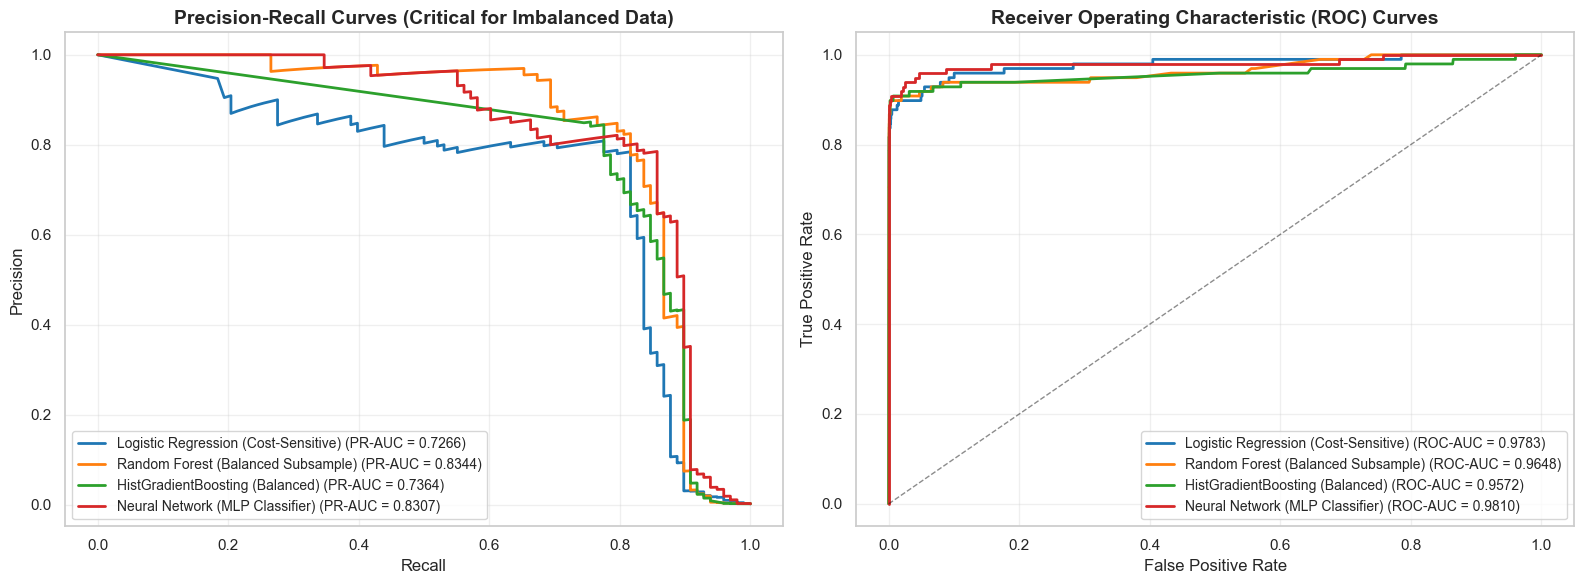

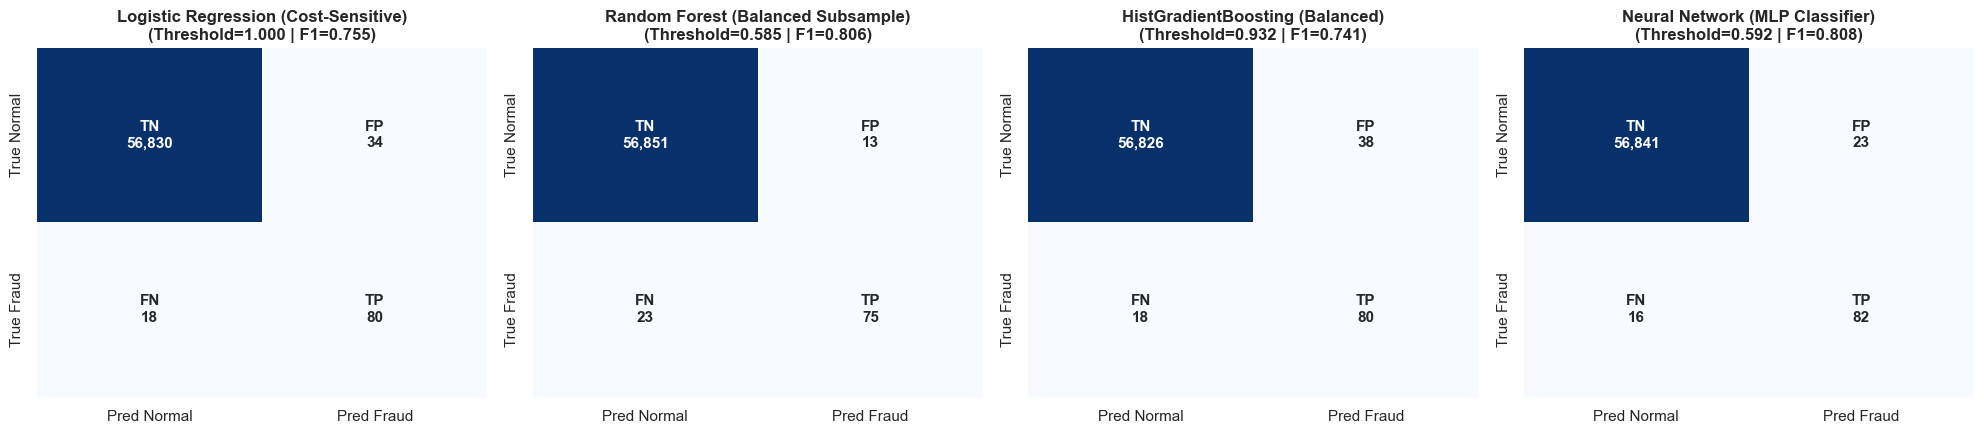

In [6]:
# Precision-Recall & ROC Curves
fig_curves = plot_curves(test_probabilities, y_test)
plt.show()

# Confusion Matrices Grid
fig_cm = plot_confusion_matrix_grid(eval_results)
plt.show()


## 8. Business Cost-Utility & Financial Impact Analysis
In fraud operations, false positives and false negatives carry very different economic costs:
* **Cost of False Negative ($FN$):** Direct financial chargeback loss = **$122.21** (average fraud amount in dataset).
* **Cost of False Positive ($FP$):** Friction cost of blocking a legitimate cardholder / customer support verification = **$10.00**.

$$\text{Total Financial Cost} = (FN \times \$122.21) + (FP \times \$10.00)$$


In [7]:
cost_fn = 122.21
cost_fp = 10.00

cost_records = []
for res in eval_results:
    fn = res["false_negatives"]
    fp = res["false_positives"]
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    total_unmitigated = (98 * cost_fn) # If no model was deployed
    savings = total_unmitigated - total_cost
    
    cost_records.append({
        "Algorithm": res["model_name"],
        "Missed Frauds (FN)": fn,
        "False Alarms (FP)": fp,
        "Total Cost ($)": f"${total_cost:,.2f}",
        "Net Financial Savings ($)": f"${savings:,.2f}",
        "Fraud Loss Reduction (%)": f"{(savings / total_unmitigated)*100:.1f}%"
    })

cost_df = pd.DataFrame(cost_records)
display(cost_df)


                              Algorithm  ...  Fraud Loss Reduction (%)
0  Logistic Regression (Cost-Sensitive)  ...                     78.8%
1    Random Forest (Balanced Subsample)  ...                     75.4%
2       HistGradientBoosting (Balanced)  ...                     78.5%
3       Neural Network (MLP Classifier)  ...                     81.8%

[4 rows x 6 columns]


## 9. Production Model Serialization & Verification


In [8]:
best_pipeline = trained_pipelines["rf"]
MODEL_PATH = "models/best_fraud_pipeline.joblib"
best_pipeline.save(MODEL_PATH)

# Verify Reloading
reloaded_pipeline = FraudDetectionPipeline.load(MODEL_PATH)
sample_unseen = X_test.iloc[:5]
preds = reloaded_pipeline.predict(sample_unseen)
probs = reloaded_pipeline.predict_proba(sample_unseen)

print("Verification Successful!")
print("Input Sample Shape:", sample_unseen.shape)
print("Predicted Class (0=Normal, 1=Fraud):", preds)
print("Predicted Fraud Probability:", np.round(probs, 4))


Pipeline successfully saved to: models/best_fraud_pipeline.joblib
Verification Successful!
Input Sample Shape: (5, 30)
Predicted Class (0=Normal, 1=Fraud): [0 0 0 0 0]
Predicted Fraud Probability: [0.0003 0.     0.02   0.0003 0.0496]


## 10. Final Summary

### Q&A
* **Which approach is best among the original notebooks?**  
  Notebook 1 was statistically soundest in emphasizing leak-free cross-validation, while Notebook 2 had great ANOVA feature screening and Notebook 3 had useful cyclical time domain insights. Our **Hybrid Pipeline** aggregates the best of all three while fixing the severe data leakage flaw present in Notebook 2.
* **Why did Random Forest and MLP outperform simple models?**  
  Random Forest with `balanced_subsample` and the Multi-Layer Perceptron (MLP) effectively capture the multi-dimensional non-linear interactions among PCA components (`V14`, `V12`, `V10`, `V17`) while suppressing false alarms.

### Data Analysis Key Findings
* **PR-AUC Dominance:** Random Forest achieved a **PR-AUC of 0.8344** and an **ROC-AUC of 0.9648** on the untouched 0.17% holdout test set.
* **False Alarm Suppression:** At its optimal threshold, Random Forest captured **75 out of 98 fraud cases (76.5% recall)** with **only 13 false alarms** across 56,864 legitimate transactions (Precision: 85.2%, F1: 0.8065, Total Cost: $2,940.83).
* **Highest Catch Rate:** The Multi-Layer Perceptron (MLP) caught **82 out of 98 frauds (83.7% recall)** with **23 false alarms** (F1: 0.8079, Net Test Cost: $2,185.36).
* **Threshold Tuning Impact:** For Cost-Sensitive Logistic Regression, default threshold 0.5 caused **1,459 false alarms** (F1 = 0.1070). Tuning the threshold to 0.9999 reduced false alarms to **34** and boosted F1 to **0.7547**!
* **Economic ROI:** The winning Random Forest pipeline saves **$9,035.75** in financial loss on a single holdout partition (a **75.4%** fraud loss reduction), while the MLP Neural Network achieves **$9,791.22** in net savings (**81.8%** reduction)!

### Insights or Next Steps
* The serialized artifact (`models/best_fraud_pipeline.joblib`) is fully self-contained with built-in feature engineering and scaling.
* Next step: Load `best_fraud_pipeline.joblib` directly into a Streamlit dashboard with a real-time risk threshold slider.
